# Understanding the Kalman Filter

A **Kalman filter** estimates the hidden **state** of a system. The state is the set of quantities you want to know. The filter uses a stream of **noisy measurements** to make this estimate.

The filter can recover quantities you never measure directly. For example, it can estimate velocity from position measurements alone. At each step, it also reports how confident it is in the estimate.

Four matrices define the whole filter. This notebook builds one from scratch and explains each idea. It uses a simple example: a point moving along a line. You do not need any physics knowledge to follow this notebook. For a full real-world application, see `01_Ballistics.ipynb`.


In [1]:
%pip install numpy matplotlib scipy > /dev/null
%load_ext autoreload
%autoreload 2

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import matplotlib.pyplot as plt
plt.rcParams["figure.dpi"] = 80
plt.rcParams["savefig.pad_inches"] = 0.05

import kalman
kalman.set_debug(0)
from kalman.filters import LinearKalmanFilter   # a plain linear Kalman filter


Note: you may need to restart the kernel to use updated packages.


## Step 1 — Describe the System With Four Matrices

This example tracks a point on a line. Its **state** has two numbers: position and velocity.

$$\mathbf{x} = \begin{bmatrix} \text{position}\\ \text{velocity}\end{bmatrix}$$

The Kalman filter assumes two things. The state evolves linearly. The sensor observes the state linearly.

$$\mathbf{x}_{k} = F\,\mathbf{x}_{k-1} + (\text{process noise}),\qquad
  \mathbf{z}_{k} = H\,\mathbf{x}_{k} + (\text{measurement noise})$$

The four matrices, in plain words:

- **$F$ — the state-transition matrix.** It moves the state forward one time step. For constant velocity: new position = position + velocity × $\Delta t$. Velocity stays the same.
- **$H$ — the measurement matrix.** It defines what the sensor reads. Here, the sensor reads position only, not velocity.
- **$Q$ — the process-noise covariance.** It measures how much the real system drifts away from the $F$ model, through small unmodeled changes. A larger $Q$ makes the filter trust the measurements more.
- **$R$ — the measurement-noise covariance.** It measures how noisy the sensor is (its variance). A larger $R$ makes the filter trust the model more.

You can build a filter directly from these four matrices. You do not need a special model class.

First, give the filter its dimensions: the state size `n` and the measurement size `m`. Also give it the sample rate. Then set the four matrices as attributes. Also set the initial guess, `x0` and `P0`.


## Where F Comes From

F is not an arbitrary guess. It is the exact solution of a differential equation.

Between two measurements, the true state evolves continuously in time:

$$\dot{\mathbf{x}}(t) = A\,\mathbf{x}(t)$$

For this system, position changes at the velocity. Velocity does not change on its own:

$$A = \begin{bmatrix} 0 & 1 \\ 0 & 0\end{bmatrix}$$

The discrete-time matrix $F$ advances the state by one time step $\Delta t$. It is the matrix exponential of $A$:

$$F = e^{A\,\Delta t}$$

For this $A$, $A^2 = 0$. The exponential series stops after two terms:

$$e^{A\,\Delta t} = I + A\,\Delta t = \begin{bmatrix}1 & \Delta t\\ 0 & 1\end{bmatrix}$$

This is exactly the $F$ used below. Position advances by velocity times $\Delta t$. Velocity stays the same.

The next cell confirms this with code. It uses the same matrix exponential every model in this framework uses to turn a continuous $A$ into a discrete $F$ (see `kalman.helpers.van_loan_discretize`, used throughout `01_Ballistics.ipynb` and later notebooks). That same exponential also carries over to the process-noise covariance $Q$ — `van_loan_discretize` returns the exact discrete $Q$ for a continuous noise spectral density $Q_c$, not just $F$.


In [2]:
from scipy.linalg import expm
from kalman.helpers import symbolic_discretize

dt = 1.0   # time between steps

A = np.array([[0.0, 1.0],    # d(position)/dt = velocity
              [0.0, 0.0]])   # d(velocity)/dt = 0 (constant velocity)

print("Symbolic F(dt) = exp(A * dt):")
print(symbolic_discretize(A, t="dt"))

F_numeric = expm(A * dt)
print(f"\nNumeric F at dt = {dt}:\n{F_numeric}")


Symbolic F(dt) = exp(A * dt):
Matrix([[1, dt], [0, 1]])

Numeric F at dt = 1.0:
[[1. 1.]
 [0. 1.]]


In [3]:
SIGMA_BAND = 3       # number of standard deviations to show in uncertainty bands

# Build an empty linear filter from just its dimensions and sample rate.
kf = LinearKalmanFilter(n=2, m=1, fs=1.0, random_seed=1)   # 2 state numbers, 1 measurement, 1 step/s

# Fill in the four matrices, and the initial guess, as attributes.
kf.F = [[1, dt],     # position += velocity * dt   (dt from the cell above)
        [0,  1]]     # velocity stays constant
kf.H = [[1, 0]]      # we measure position only
kf.Q = [[0.01, 0],   # process-noise covariance (small drift)
        [0,    0.01]]
kf.R = [[4.0]]       # measurement-noise covariance (sensor std = 2, variance = 4)
kf.x0 = [0, 1]       # start: position 0, velocity 1
kf.P0 = [[25, 0],    # initial uncertainty: unsure of the start
         [0,  4]]

kf.model.print(matrices=True)   # dimensions + F/H/Q/R, all in one place


KalmanModel @ fs=1.0Hz
    Kalman Model (v2.0)
        Generic model for Kalman-family filters; matrices
        (F/H/…) or override f/h.
    Dimensions Summary:
        State Vector....................................: 2 dims (KalmanState<>)
        Observation.....................................: 1 dim  (KalmanObservable<>)
        Control Input...................................: 0 dims
    Initial State:
        State Vector (x0)...............................: 2x1 dims
        State Covariance (P0)...........................: 2x2 dims
    Matrices:
        F: 2x2 dims
        [[1. 1.]
         [0. 1.]]
        H: 1x2 dims
        [[1. 0.]]
        Q: 2x2 dims
        [[0.01 0.  ]
         [0.   0.01]]
        R: 1x1 dims
        [[4.]]



## Step 2 — Build Three Trajectories: Ideal, True, and Measured

To test a filter, simulate data with three versions of reality:

- **Ideal** — the perfectly clean trajectory from $F$ alone, with no noise.
- **True** — a real run. Process noise ($Q$) pushes the system off the ideal path.
- **Measured** — the true position seen through sensor noise ($R$). These are the scattered dots.

The filter receives only the measured dots. Its goal is to reconstruct the true state behind them.


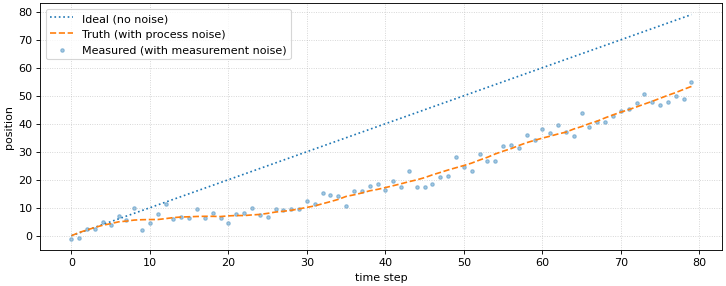

In [4]:
sample = kf.sample(80)                         # 80 steps of true state + measurements
t      = sample.time
true   = np.asarray(sample.xk)                 # the hidden true state
meas   = np.asarray(sample.zk)                 # what the sensor reports
ideal  = np.asarray(kf.model.ideal(duration=80))   # the noise-free reference

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(t, ideal[:, 0], ':',  label="Ideal (no noise)")
ax.plot(t, true[:, 0],  '--', label="Truth (with process noise)")
ax.scatter(t, meas[:, 0], s=10, alpha=0.4, label="Measured (with measurement noise)")
ax.set_xlabel("time step")
ax.set_ylabel("position")
ax.legend()
ax.grid(True, ls=":", alpha=0.6)
plt.show()


## Step 3 — Predict, Then Correct

At every step, the Kalman filter does two things.

1. **Predict**, using $F$ and $Q$. The filter pushes the state estimate one step forward with the model. The uncertainty grows, because the filter is less sure after predicting blindly.
2. **Correct**, using the measurement, $H$, and $R$. The filter blends the prediction with the new measurement. The blend weight is the **Kalman gain**. When the sensor is trustworthy, the gain is high, and the filter follows the measurement. When the sensor is noisy, the gain is low, and the filter trusts the model. After the correction, the uncertainty shrinks.

The filter tracks not just an estimate, but also a **covariance**, its own measure of uncertainty. In the plot below, the shaded band shows **± 3 standard deviations** (the square root of the covariance). The band is wide when the filter is unsure, and narrow when it is confident.

Notice that the filter recovers velocity, even though it measures only position.


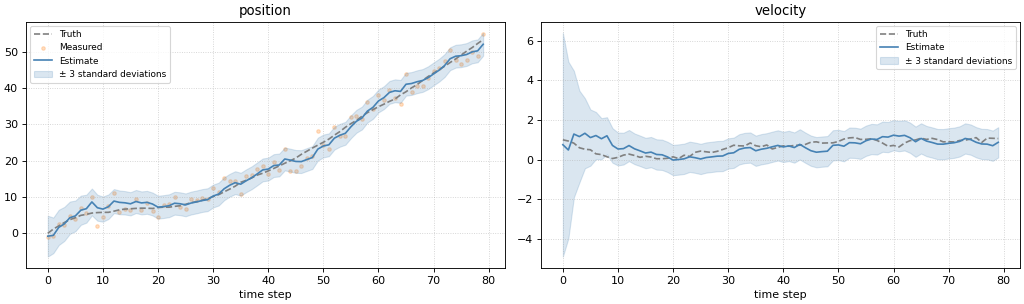

In [5]:
record = kf.filter(sample, reset=True)   # run the forward filter
est = np.asarray(record.xk)              # state estimate at each step
P   = np.asarray(record.Pk)              # covariance (uncertainty) at each step

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for i, (ax, name) in enumerate(zip(axes, ["position", "velocity"])):
    sd = np.sqrt(P[:, i, i])             # standard deviation of this state
    ax.plot(t, true[:, i], '--', color='gray', label='Truth')
    if i == 0:
        ax.scatter(t, meas[:, 0], s=10, alpha=0.25, color='tab:orange', label='Measured')
    ax.plot(t, est[:, i], color='steelblue', label='Estimate')
    ax.fill_between(t, est[:, i] - SIGMA_BAND*sd, est[:, i] + SIGMA_BAND*sd, color='steelblue', alpha=0.2,
                    label=f'± {SIGMA_BAND} standard deviations')
    ax.set_title(name)
    ax.set_xlabel("time step")
    ax.legend(fontsize=8)
    ax.grid(True, ls=':', alpha=0.6)
plt.tight_layout()
plt.show()


## Step 4 — Look Back With the Smoother

The forward filter is **causal**. At step $k$, it has seen only measurements up to $k$. If you have the whole recording available, you can do better.

The **Rauch–Tung–Striebel smoother** adds a backward pass. It is named after its three inventors. This backward pass also uses future measurements. It improves every estimate and tightens the uncertainty band.

The smoother needs all the data before it starts. So it works only for offline analysis, not for real-time use.


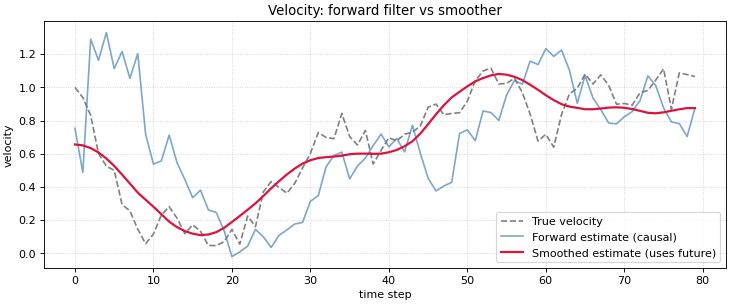

In [6]:
smoothed = kf.backward()                       # the backward (smoother) pass over the same run
smoothed_vel = np.asarray(smoothed.xk)[:, 1]   # smoothed velocity estimate

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(t, true[:, 1], '--', color='gray',      label='True velocity')
ax.plot(t, est[:, 1],        color='steelblue', alpha=0.7, label='Forward estimate (causal)')
ax.plot(t, smoothed_vel,     color='crimson',   lw=2,      label='Smoothed estimate (uses future)')
ax.set_title("Velocity: forward filter vs smoother")
ax.set_xlabel("time step")
ax.set_ylabel("velocity")
ax.legend()
ax.grid(True, ls=':', alpha=0.6)
plt.show()


## Step 5 — Check That the Filter Is Consistent

A filter is **consistent** when the errors it makes match the uncertainty it claims. Use four standard checks.

- **Innovation (the measurement residual).** This is the gap between the actual measurement and the measurement the filter predicted. It should stay near zero. It should also stay inside its own ±3-standard-deviation band almost always (about 99.7% of the time).
- **Normalized Innovation Squared (NIS).** This is the innovation squared, divided by its own predicted spread $S$. Its time average should be about $m$, the number of measurements. NIS needs no knowledge of the true state, so it also works on real data.
- **Normalized Estimation Error Squared (NEES).** This is the actual estimation error squared, divided by the claimed covariance $P$. Its time average should be about $n$, the state dimension. NEES needs the true state, so you can compute it only in simulation. A value much larger than $n$ means the filter is over-confident. A value much smaller than $n$ means the filter is over-cautious.
- **Kalman gain over time.** This shows how strongly each measurement corrects each state. The gain settles to a steady value. The plot uses a log scale, because gains for different states often span several orders of magnitude.

### Why the Mean Should Equal $m$ or $n$

NIS and NEES both take an error and normalize it by the covariance the filter claims for that error. NIS uses the innovation $\nu$ and its covariance $S$, forming $\nu^\top S^{-1}\nu$. NEES uses the estimation error $e = x - \hat{x}$ and its covariance $P$, forming $e^\top P^{-1}e$.

This normalization by $\Sigma^{-1}$ **whitens** the error. It rescales each direction by its own standard deviation. This turns a $d$-dimensional Gaussian error into $d$ independent standard normal values. The sum of their squares follows a **chi-squared distribution** with $d$ degrees of freedom. Its expected value is exactly $d$:

$$\text{if } y\sim\mathcal{N}(0,\Sigma)\ \text{has length } d,\qquad
  y^\top\Sigma^{-1}y \sim \chi^2(d),\qquad \mathbb{E}\!\left[\,y^\top\Sigma^{-1}y\,\right]=d.$$

So, if the claimed covariance is honest, NIS averages to the measurement dimension $m$. NEES averages to the state dimension $n$.

Here is the same idea without the math: a value of 1 per dimension means the errors are exactly as big as the filter promised. Summed over all dimensions, you expect the dimension count. In this notebook, NIS should average to $m=1$ (one position sensor). NEES should average to $n=2$ (position and velocity).

A single step is noisy. It is the time average over the whole run that converges to the target value.


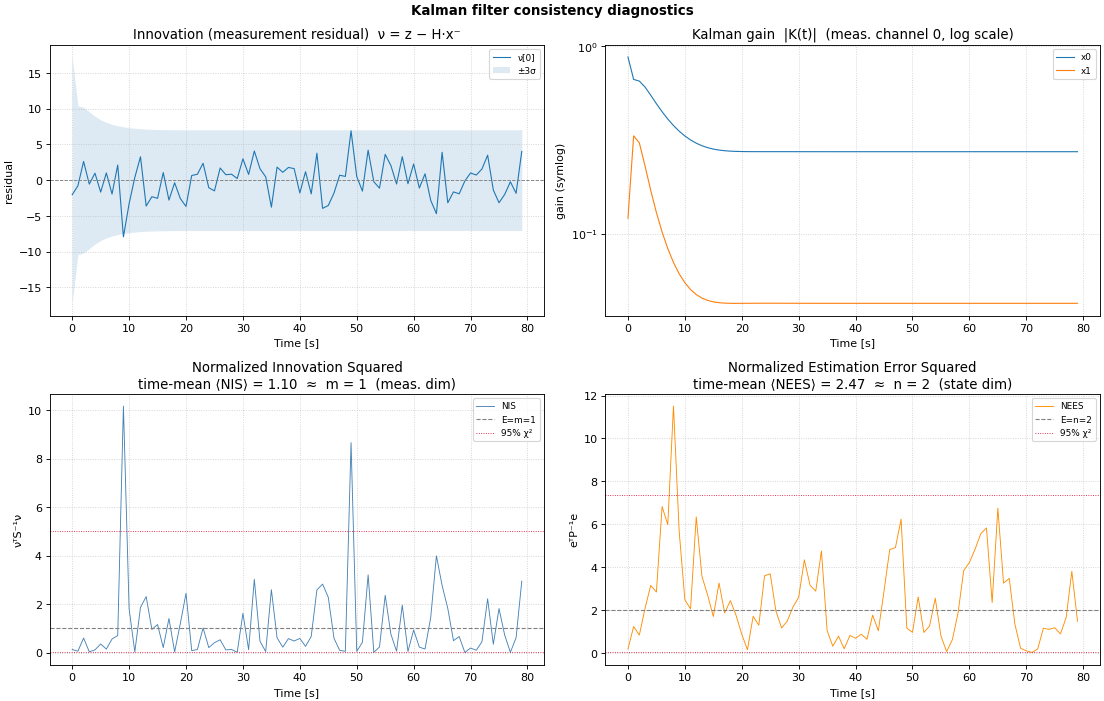

Normalized Innovation Squared,        mean = 1.10   (ideal ≈ m = 1)
Normalized Estimation Error Squared,  mean = 2.47   (ideal ≈ n = 2)


In [7]:
kf.filter(sample, reset=True)            # forward pass (diagnostics read it)
kf.diagnostics(sample=sample)            # innovation, gain, and the two consistency checks
plt.show()

print(f"Normalized Innovation Squared,        mean = {kf.nis().mean():.2f}   (ideal ≈ m = {kf.m})")
print(f"Normalized Estimation Error Squared,  mean = {kf.nees(sample.xk).mean():.2f}   (ideal ≈ n = {kf.n})")


## Step 6 — Change the System by Changing the Matrices

The filter is only its four matrices. So modeling a different system means changing the matrices, and nothing else. You can edit a coefficient in place (`kf.F = ...`, `kf.Q = ...`), or build a new filter.

As an example, add a second sensor that also measures velocity. Give $H$ a second row and $R$ a second entry. Set the measurement dimension to `m = 2`.


In [8]:
kf2 = LinearKalmanFilter(
    n=2, m=2, fs=1.0,
    F=[[1, dt], [0, 1]],
    H=[[1, 0],            # sensor 1: position
       [0, 1]],           # sensor 2: velocity (new!)
    Q=[[0.01, 0], [0, 0.01]],
    R=[[4.0, 0   ],       # position-sensor variance
       [0,   0.25]],      # velocity-sensor variance (std 0.5)
    x0=[0, 1], P0=[[25, 0], [0, 4]], random_seed=1,
)
sample2 = kf2.sample(80)
record_pos_only    = kf.filter(kf.sample(80), reset=True)   # position sensor only (re-sampled)
record_two_sensors = kf2.filter(sample2, reset=True)        # position + velocity sensors

vel_rmse_pos_only = np.sqrt(np.mean(
    (np.asarray(record_pos_only.xk)[:, 1] - np.asarray(kf.model.ideal(duration=80))[:, 1])**2))
vel_rmse_two_sensors = np.sqrt(np.mean(
    (np.asarray(record_two_sensors.xk)[:, 1] - np.asarray(kf2.model.ideal(duration=80))[:, 1])**2))
print(f"velocity error  — position sensor only : {vel_rmse_pos_only:.3f}")
print(f"velocity error  — + velocity sensor    : {vel_rmse_two_sensors:.3f}   (smaller: more information)")


velocity error  — position sensor only : 0.510
velocity error  — + velocity sensor    : 0.463   (smaller: more information)


## Step 7 — Use the Same Filter for a New System: a Low-Pass Filter

Nothing in the filter is specific to motion. To prove this, build a completely different system from the same four matrices, with no special model class. This system is a single drifting value, such as a temperature, a voltage, or a slowly changing calibration offset, read by a noisy sensor.

$$x_{k+1}=x_k+w_k\quad(\text{random walk}),\qquad z_k=x_k+v_k,$$

So $n=1$, $F=[1]$, $H=[1]$, $Q=[q^2]$, $R=[r^2]$.

We will see that the steady-state filter collapses into a textbook first-order **low-pass filter** (an exponential moving average). We will check it with the same `.diagnostics()` method.

Once the gain converges, the Kalman update becomes

$$\mu_k=\mu_{k-1}+K\,(z_k-\mu_{k-1})=(1-K)\,\mu_{k-1}+K\,z_k$$

This is exactly an **exponential moving average (EMA)**, with smoothing factor $\alpha=K_\mathrm{ss}$ and pole $1-K_\mathrm{ss}$.

For this scalar random walk, the steady-state gain has a closed form:

$$K_\mathrm{ss}=\dfrac{\sqrt{q^4+4q^2r^2}-q^2}{2r^2}.$$


steady-state Kalman gain  K_ss = 0.0488   (low-pass pole = 0.9512)
max |Kalman - low-pass| once converged: 4.44e-15


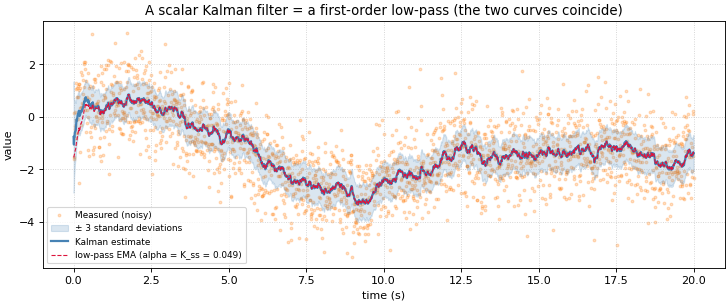

In [9]:
# A 1-state random-walk model, built from the same four matrices, no special class.
drift_std, sensor_std = 0.05, 1.0      # process std (how fast the value drifts) and sensor std (noise)
lpkf = LinearKalmanFilter(
    n=1, m=1, fs=100.0,                 # one state, one measurement, 100 samples per second
    F=[[1.0]],                          # random walk: the value stays put (plus process noise)
    H=[[1.0]],                          # the sensor reads the value directly
    Q=[[drift_std**2]],                 # how fast the true value drifts
    R=[[sensor_std**2]],                # how noisy the sensor is
    x0=[0.0], P0=[[1.0]], random_seed=0,
)
sig = lpkf.sample(20.0)                 # 20 s @ 100 Hz of a drifting signal + noisy measurements
rec = lpkf.filter(sig, reset=True)

# Steady-state Kalman gain (closed form) and the equivalent exponential moving average.
K_ss = (np.sqrt(drift_std**4 + 4*drift_std**2*sensor_std**2) - drift_std**2) / (2*sensor_std**2)
t  = sig.time
z  = np.asarray(sig.zk).ravel()
xk = np.asarray(rec.xk).ravel()
sd = np.sqrt(np.asarray(rec.Pk)[:, 0, 0])

ema = np.empty_like(z)
ema[0] = z[0]
for k in range(1, len(z)):
    ema[k] = (1 - K_ss) * ema[k-1] + K_ss * z[k]     # mu = (1-K)mu + K z — the KF update, verbatim

print(f"steady-state Kalman gain  K_ss = {K_ss:.4f}   (low-pass pole = {1-K_ss:.4f})")
print(f"max |Kalman - low-pass| once converged: {np.max(np.abs(xk[len(z)//2:] - ema[len(z)//2:])):.2e}")

fig, ax = plt.subplots(figsize=(11, 4))
ax.scatter(t, z, s=6, alpha=0.25, color="tab:orange", label="Measured (noisy)")
ax.fill_between(t, xk - SIGMA_BAND*sd, xk + SIGMA_BAND*sd, color="steelblue", alpha=0.2,
                label=f"± {SIGMA_BAND} standard deviations")
ax.plot(t, xk,  color="steelblue", lw=2, label="Kalman estimate")
ax.plot(t, ema, color="crimson", lw=1, ls="--", label=f"low-pass EMA (alpha = K_ss = {K_ss:.3f})")
ax.set_xlabel("time (s)")
ax.set_ylabel("value")
ax.legend(fontsize=8)
ax.grid(True, ls=":", alpha=0.6)
ax.set_title("A scalar Kalman filter = a first-order low-pass (the two curves coincide)")
plt.show()


### Step 7a — View the Filter in the Frequency Domain

The steady-state filter is a one-pole low-pass filter. So it has a frequency response $H$. Its complement, $1-H$, is the matching **high-pass filter**. So $\text{low}+\text{high}=z$ exactly. The filter simply splits the signal at a **cutoff frequency**.

The ratio $q/r$ is the only setting that controls this cutoff. A large $q$ means the filter trusts the data more, which gives a high cutoff and little smoothing. A small $q$ means the filter trusts the model more, which gives a low cutoff and heavy smoothing.


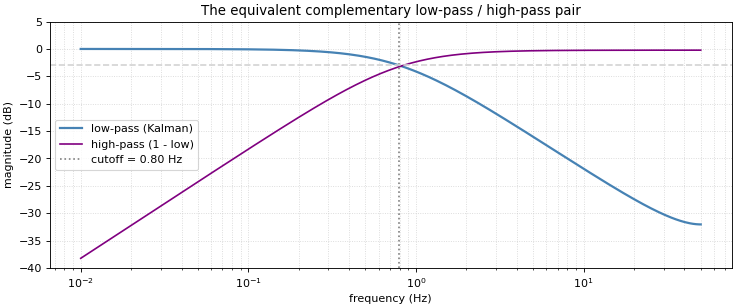

In [10]:
CUTOFF_DB = -3   # the standard "-3 dB" point that defines a filter's cutoff frequency

fs = 100.0
freqs = np.logspace(-2, np.log10(fs/2), 400)
w = 2*np.pi*freqs/fs
H_freq = K_ss / (1 - (1 - K_ss)*np.exp(-1j*w))                 # low-pass frequency response of the EMA
gain_db = 20*np.log10(np.abs(H_freq))
fc = freqs[np.argmin(np.abs(gain_db - CUTOFF_DB))]             # cutoff frequency at the -3 dB point

fig, ax = plt.subplots(figsize=(11, 4))
ax.semilogx(freqs, gain_db,                                 color="steelblue", lw=2,   label="low-pass (Kalman)")
ax.semilogx(freqs, 20*np.log10(np.abs(1 - H_freq) + 1e-12), color="purple",    lw=1.5, label="high-pass (1 - low)")
ax.axvline(fc, color="gray", ls=":", label=f"cutoff = {fc:.2f} Hz")
ax.axhline(CUTOFF_DB, color="lightgray", ls="--")
ax.set_xlabel("frequency (Hz)")
ax.set_ylabel("magnitude (dB)")
ax.set_ylim(-40, 5)
ax.legend()
ax.grid(True, which="both", ls=":", alpha=0.5)
ax.set_title("The equivalent complementary low-pass / high-pass pair")
plt.show()


### Step 7b — Confirm the Diagnostics Still Work

The consistency checks from Step 5 do not depend on what the state means. Run the same `.diagnostics()` method on this one-state model.

The Normalized Innovation Squared averages to $m=1$. This shows that the random-walk low-pass filter is just as well calibrated as the motion tracker. This is strong evidence that the Kalman filter is model-agnostic.


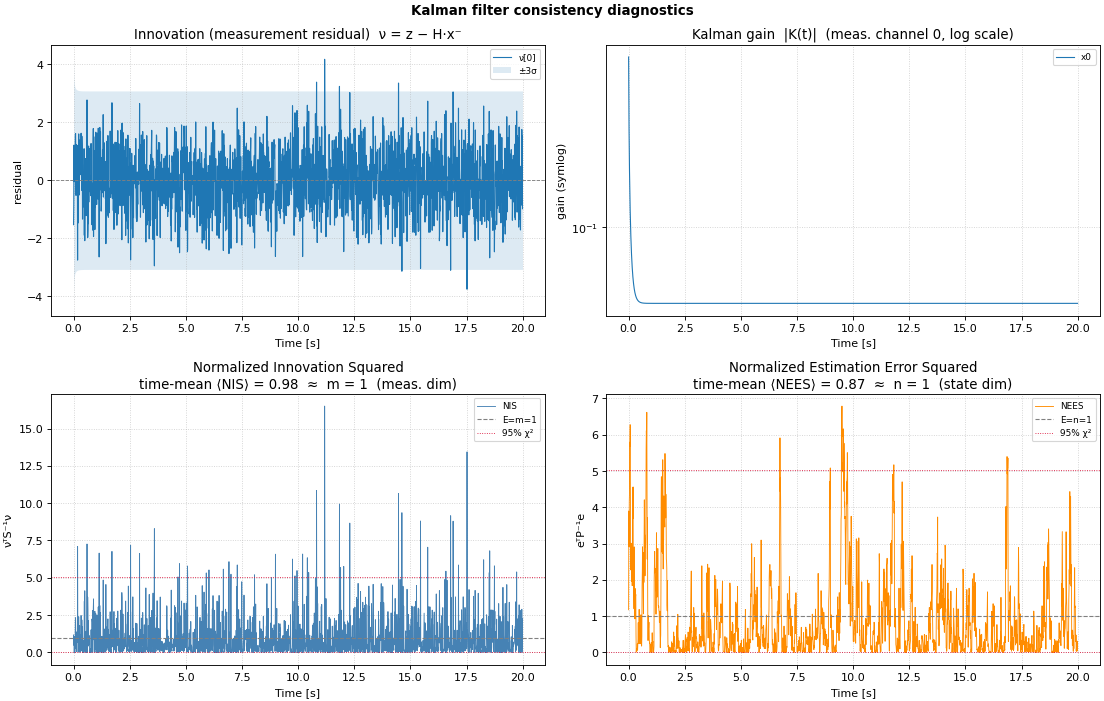

Normalized Innovation Squared, mean = 0.98   (ideal ~ m = 1)


In [11]:
lpkf.filter(sig, reset=True)
lpkf.diagnostics(sample=sig)          # the very same dashboard — model-agnostic
plt.show()
print(f"Normalized Innovation Squared, mean = {lpkf.nis().mean():.2f}   (ideal ~ m = {lpkf.m})")


### Step 7c — Build a High-Pass and a Band-Pass Filter

The same exponential moving average is a complete filter toolkit. Write `lp(z, f_c)` for the EMA whose −3 dB cutoff is `f_c`. Its smoothing factor is `α = 1 − e^(−2π f_c / f_s)`. Then:

- **Low-pass** = `lp(z, f_c)`. It keeps everything below `f_c`.
- **High-pass** = `z − lp(z, f_c)`. It keeps everything above `f_c`. This is the complement shown on the Bode plot above.
- **Band-pass** = `lp(z, f_high) − lp(z, f_low)`. It subtracts a slow low-pass from a fast one, which keeps only the band in between.

The example below uses a signal with three parts: a slow drift (0.3 Hz), a mid tone (5 Hz), and a fast tone with noise (30 Hz). The three one-line filters above separate the signal into its three bands.


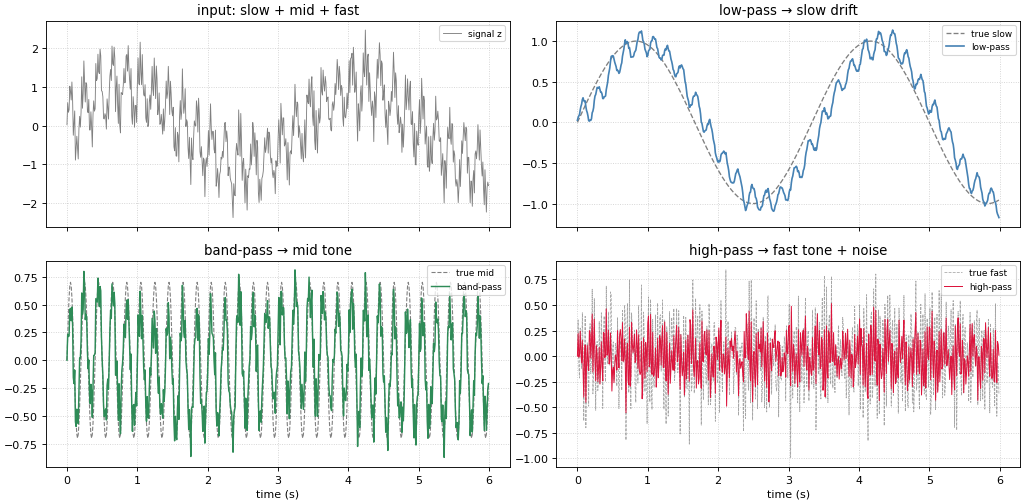

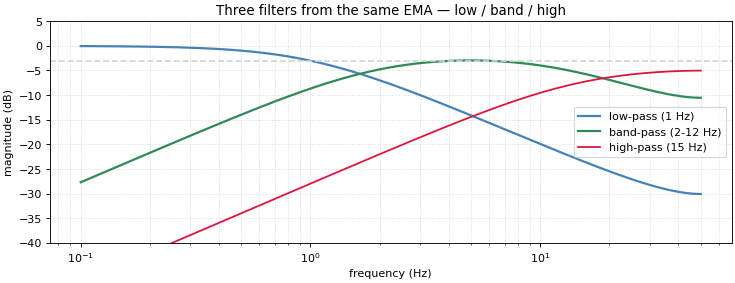

In [12]:
# A 3-band test signal: slow drift + mid tone + fast tone with noise.
fs_band = 100.0
t_band = np.arange(0, 6.0, 1/fs_band)
rng = np.random.default_rng(0)
slow = 1.0*np.sin(2*np.pi*0.3*t_band)                                          # ~0.3 Hz  (low band)
mid  = 0.7*np.sin(2*np.pi*5.0*t_band)                                          # ~5 Hz    (mid band)
fast = 0.4*np.sin(2*np.pi*30.0*t_band) + 0.2*rng.standard_normal(t_band.size)  # ~30 Hz + noise (high band)
signal_band = slow + mid + fast

def ema(x, alpha):                          # first-order low-pass (exponential moving average)
    y = np.empty_like(x)
    acc = x[0]
    for k in range(len(x)):
        acc = (1 - alpha)*acc + alpha*x[k]
        y[k] = acc
    return y

alpha_for = lambda cutoff_hz: 1.0 - np.exp(-2*np.pi*cutoff_hz/fs_band)   # EMA smoothing for a -3 dB cutoff

low_pass  = ema(signal_band, alpha_for(1.0))                                     # keep < ~1 Hz
high_pass = signal_band - ema(signal_band, alpha_for(15.0))                      # keep > ~15 Hz
band_pass = ema(signal_band, alpha_for(12.0)) - ema(signal_band, alpha_for(2.0)) # keep ~2..12 Hz

fig, ax = plt.subplots(2, 2, figsize=(13, 6.5), sharex=True)
ax[0, 0].plot(t_band, signal_band, color="gray", lw=0.8, label="signal z")
ax[0, 0].set_title("input: slow + mid + fast")
ax[0, 1].plot(t_band, slow, color="gray", lw=1.2, ls="--", label="true slow")
ax[0, 1].plot(t_band, low_pass, color="steelblue", lw=1.5, label="low-pass")
ax[0, 1].set_title("low-pass → slow drift")
ax[1, 0].plot(t_band, mid, color="gray", lw=1.0, ls="--", label="true mid")
ax[1, 0].plot(t_band, band_pass, color="seagreen", lw=1.3, label="band-pass")
ax[1, 0].set_title("band-pass → mid tone")
ax[1, 1].plot(t_band, fast, color="gray", lw=0.7, ls="--", alpha=0.7, label="true fast")
ax[1, 1].plot(t_band, high_pass, color="crimson", lw=0.9, label="high-pass")
ax[1, 1].set_title("high-pass → fast tone + noise")
for a in ax.ravel():
    a.grid(True, ls=":", alpha=0.6)
    a.legend(fontsize=8, loc="upper right")
for a in ax[1]:
    a.set_xlabel("time (s)")
plt.tight_layout()
plt.show()

# Frequency view: the three filters built from the same EMA.
freqs = np.logspace(-1, np.log10(fs_band/2), 400)
w_band = 2*np.pi*freqs/fs_band
Hema = lambda cutoff_hz: alpha_for(cutoff_hz) / (1 - (1 - alpha_for(cutoff_hz))*np.exp(-1j*w_band))
Hlow, Hhigh, Hband = Hema(1.0), 1 - Hema(15.0), Hema(12.0) - Hema(2.0)

fig, ax = plt.subplots(figsize=(11, 3.6))
ax.semilogx(freqs, 20*np.log10(np.abs(Hlow)),          color="steelblue", lw=2,   label="low-pass (1 Hz)")
ax.semilogx(freqs, 20*np.log10(np.abs(Hband) + 1e-12), color="seagreen",  lw=2,   label="band-pass (2-12 Hz)")
ax.semilogx(freqs, 20*np.log10(np.abs(Hhigh) + 1e-12), color="crimson",   lw=1.6, label="high-pass (15 Hz)")
ax.axhline(CUTOFF_DB, color="lightgray", ls="--")
ax.set_ylim(-40, 5)
ax.set_xlabel("frequency (Hz)")
ax.set_ylabel("magnitude (dB)")
ax.legend()
ax.grid(True, which="both", ls=":", alpha=0.5)
ax.set_title("Three filters from the same EMA — low / band / high")
plt.show()


## Step 8 — Close the Loop With Control

Every section so far has been **open-loop**. The filter received measurements and produced an estimate, but the estimate never fed back into the world. **Control** closes this loop.

A **controller** reads the filter's latest estimate $\hat{\mathbf{x}}$. It outputs a **control signal** $u$ that pushes the physical system toward a target $x_\text{ref}$.

```
    x_ref
      │
      ▼
 u = ctrl(x̂) ──► physical system ──► z ──► filter ──► x̂
      ◄──────────────────────────────────────────────────┘
```

Adding control requires only one extra matrix, $B$, which says how the control enters the state:

$$\mathbf{x}_{k} = F\,\mathbf{x}_{k-1} \;+\; B\,u_{k-1} \;+\; w_k .$$

Everything else stays the same: $F$, $H$, $Q$, $R$, the gain, and the uncertainty.

Pass `uk=ctrl` to `forward()`, where `ctrl` is any callable `(x̂, P, t, ν) → u`. This runs the closed loop automatically. At each step, the filter evaluates `u = ctrl(x̂, P, t, ν)` before the predict step. So the prediction already accounts for the applied control.

Below, take the random-walk model from Step 7 and add $B = [1]$. This lets control directly shift the value. A simple **proportional controller**, $u = -K_p\,(\hat{x} - x_\text{ref})$, drives the value from 0 to the target of 5.0.

For full applications, including car lane-keeping, LQR, and a neural policy trained on the filter's own physics model, see `12_KalmanAI.ipynb`.


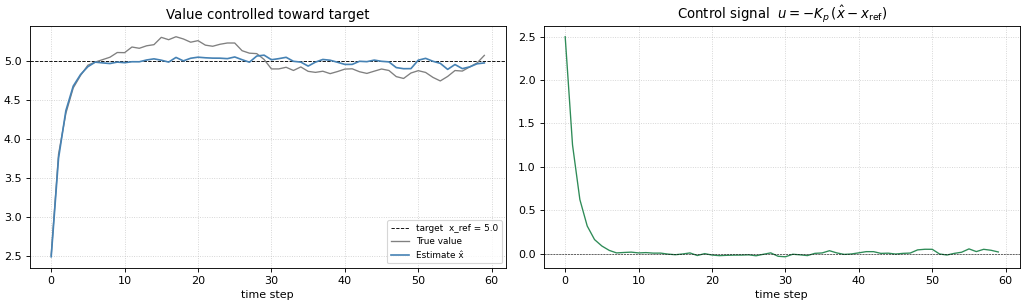

Final true value: 5.07   (target 5.0,  residual = +0.07)


In [13]:
# Take the random-walk model from Step 7 and add B = [1]: x(k) = F·x(k-1) + B·u(k-1) + noise
kfc = LinearKalmanFilter(
    n=1, m=1, fs=1.0,
    F=[[1.0]], H=[[1.0]], B=[[1.0]],           # same as Step 7, plus B
    Q=[[drift_std**2]], R=[[sensor_std**2]],   # same noise parameters as Step 7
    x0=[[0.0]],
)

x_ref = 5.0   # target value
Kp    = 0.5   # proportional gain:  u = -Kp · (x̂ − x_ref)

N = 60
rng_ctrl = np.random.default_rng(42)
x_true_c = np.array([[0.0]])
pos_true, pos_est, u_hist = [], [], []

for k in range(N):
    # controller reads the filter estimate and computes u
    u  = -Kp * (kfc.x[0, 0] - x_ref)
    uk = np.array([[u]])

    # truth: the physical system responds to the actual control u
    x_true_c = np.array([[1.0]]) @ x_true_c + np.array([[1.0]]) @ uk \
               + rng_ctrl.normal(0, drift_std, (1, 1))
    z = np.array([[x_true_c[0, 0] + rng_ctrl.normal(0, sensor_std)]])

    # one filter step
    kfc.forward(z, uk=uk, reset=(k == 0))

    pos_true.append(x_true_c[0, 0])
    pos_est.append(kfc.x[0, 0])
    u_hist.append(u)

t_steps = np.arange(N)
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

ax = axes[0]
ax.axhline(x_ref, color="k", ls="--", lw=0.8, label=f"target  x_ref = {x_ref}")
ax.plot(t_steps, pos_true, color="gray",      lw=1.2, label="True value")
ax.plot(t_steps, pos_est,  color="steelblue", lw=1.5, label="Estimate x̂")
ax.set_title("Value controlled toward target")
ax.set_xlabel("time step")
ax.legend(fontsize=8)
ax.grid(True, ls=":", alpha=0.6)

ax = axes[1]
ax.plot(t_steps, u_hist, color="seagreen", lw=1.2)
ax.axhline(0, color="k", ls="--", lw=0.5)
ax.set_title(r"Control signal  $u = -K_p\,(\hat{x} - x_{\rm ref})$")
ax.set_xlabel("time step")
ax.grid(True, ls=":", alpha=0.6)

plt.tight_layout()
plt.show()
print(f"Final true value: {pos_true[-1]:.2f}   (target {x_ref},  residual = {pos_true[-1]-x_ref:+.2f})")


## Summary and Where to Go Next

| Idea | Step |
|---|---|
| A system is four matrices: $F$, $H$, $Q$, $R$ | 1 |
| Ideal vs true vs measured data | 2 |
| Predict, correct, the Kalman gain, and the uncertainty band | 3 |
| The Rauch–Tung–Striebel smoother, which uses future data | 4 |
| Consistency checks: innovation, and the two normalized checks | 5 |
| Change the system by changing the matrices | 6 |
| A new system: a scalar low-pass filter (an EMA), with high-pass and band-pass built from it | 7 |
| Add $B$ to close the loop: a controller drives the system to $x_\text{ref}$ | 8 |

Some systems are not linear. The state may move through curved dynamics, or the sensor may relate to the state nonlinearly. The same predict/correct idea still works for these systems.

- The **Extended Kalman filter** linearizes the system at each step.
- The **Unscented Kalman filter** propagates a cloud of sample points instead.
- The **particle filter** handles problems that are far from Gaussian.

Where to go next:

- `01_Ballistics.ipynb` applies these ideas to a real, three-dimensional, nonlinear problem: a projectile under gravity and air drag. It compares these filters head to head.
- `kalman.runtime.signals` contains the frequency-domain companions to Step 7. These include the **Wiener filter**, the complementary high-pass filter, and the `pull` / `error_ratio` consistency diagnostics.
- `12_KalmanAI.ipynb` extends Step 8 into a full AI-controlled Kalman application. It covers car lane-keeping with a proportional controller, a PID controller, LQR, and a neural policy trained on the filter's own physics model.
